# Comparing rzsynth with Ross–Selinger and Solovay–Kitaev

For each angle θ and target error ε, this notebook synthesises the phase gate $P(\theta)=\mathrm{diag}(1,e^{i\theta})$ with three methods, checks every circuit's error independently, and tabulates the gate counts.

| method | gate set | qubits | error definition |
|---|---|---|---|
| **rzsynth** (ours) | H, X, Z, CX, CCX | 3: q0 data, q1 imaginary part, q2 clean ancilla | exact phase, on the realified gate $M_P(\theta)$ |
| **Ross–Selinger** (`pygridsynth`) | Clifford+T | 1 | $R_z(\theta)$ up to global phase |
| **Solovay–Kitaev** (Qiskit) | H, T, T† | 1 | $R_z(\theta)$ up to global phase |

**Requirements:** put `rzsynth.py` in the same folder as this notebook, and install the packages in the next cell if needed.

In [2]:
# %pip install pygridsynth qiskit mpmath pandas matplotlib

## 1. Parameters

In [3]:
import numpy as np
n=15
angle = (np.arange(n) + (np.sqrt(5) - 1) / 2) / n   # n evenly spaced points, shifted by an irrational offset
ANGLES   = [2*np.pi*i for i in angle]      # theta values: no multiple of pi/4 (those are exact in Clifford+T)
EPS_LIST = [1e-2, 1e-3, 1e-4, 1e-5]
OURS     = dict(allow_cx=True, beam=64, tries=4)   # rzsynth options; try e.g. dict(allow_cx=False, beam=None)
SK_MAX_DEGREE = 6                                  # Qiskit SK: larger degrees grow ~5x in size per step

## 2. Imports and helpers

In [4]:
import time, pandas as pd, mpmath
import rzsynth as RZ
from pygridsynth.gridsynth import gridsynth_gates
from qiskit import QuantumCircuit
from qiskit.circuit.library import RZGate
from qiskit.quantum_info import Operator
from qiskit.synthesis import SolovayKitaevDecomposition

mpmath.mp.dps = 128          # gridsynth needs high-precision arithmetic

def dist_up_to_phase(A, B):
    """Operator-norm distance between A and B, minimised over a global phase."""
    M = B.conj().T @ A
    return np.linalg.norm(A - (np.trace(M) / abs(np.trace(M))) * B, 2)

# 1-qubit Clifford+T matrices for evaluating gridsynth strings (W = global phase e^{i pi/4})
w = np.exp(1j * np.pi / 4)
CT = {'H': np.array([[1, 1], [1, -1]]) / np.sqrt(2), 'T': np.diag([1, w]), 'S': np.diag([1, 1j]),
      'X': np.array([[0, 1], [1, 0]]), 'W': w * np.eye(2)}

In [ ]:
def run_ours(theta, eps):
    t = time.time(); r = RZ.synthesize_p(theta, eps, **OURS); dt = time.time() - t
    # independent check with Qiskit: load the circuit from QASM, compare its 4 input columns with M_P
    U = Operator(QuantumCircuit.from_qasm_str(RZ.to_qasm(r['gates']))).data
    err = np.linalg.norm(U[:, :4] - np.array(RZ.target_columns(theta)), 2)
    c = r['counts']
    return dict(T=None, H=c.get('H', 0), CX=c.get('CX', 0), CCX=c.get('CCX', 0),
                total=c['total'], error=err, seconds=dt)

def run_gridsynth(theta, eps):
    t = time.time(); s = gridsynth_gates(theta=mpmath.mpf(theta), epsilon=mpmath.mpf(eps)); dt = time.time() - t
    U = np.eye(2, dtype=complex)
    for ch in s:
        U = U @ CT[ch]
    err = dist_up_to_phase(U, RZGate(theta).to_matrix())
    n = {g: s.count(g) for g in 'HTSX'}               # W is a global phase, not a gate
    return dict(T=n['T'], H=n['H'], CX=0, CCX=0, total=sum(n.values()), error=err, seconds=dt)

SK = SolovayKitaevDecomposition(basis_gates=['h', 't', 'tdg'], depth=10)
def run_sk(theta, eps):
    """Smallest recursion degree whose circuit reaches eps (None if none up to SK_MAX_DEGREE)."""
    target = RZGate(theta).to_matrix()
    for n in range(SK_MAX_DEGREE + 1):
        t = time.time(); qc = SK.run(target, recursion_degree=n); dt = time.time() - t
        err = dist_up_to_phase(Operator(qc).data, target)
        if err <= eps:
            ops = dict(qc.count_ops())
            return dict(T=ops.get('t', 0) + ops.get('tdg', 0), H=ops.get('h', 0), CX=0, CCX=0,
                        total=sum(ops.values()), error=err, seconds=dt, sk_degree=n)
    return None

In [24]:
n = 15
angle = np.linspace(0,1,n+2)
angle = np.delete(angle, [n+1])
angle = np.delete(angle, [0])
angle = [i/2 for i in angle]
angle2 = [2*i for i in angle]

print("Angles of sqrt(U) that we actually implement via iQPE: ", angle)
print("Angles of U that we can directly implement via new iQPE: ", angle2)

Angles of sqrt(U) that we actually implement via iQPE:  [np.float64(0.03125), np.float64(0.0625), np.float64(0.09375), np.float64(0.125), np.float64(0.15625), np.float64(0.1875), np.float64(0.21875), np.float64(0.25), np.float64(0.28125), np.float64(0.3125), np.float64(0.34375), np.float64(0.375), np.float64(0.40625), np.float64(0.4375), np.float64(0.46875)]
Angles of U that we can directly implement via new iQPE:  [np.float64(0.0625), np.float64(0.125), np.float64(0.1875), np.float64(0.25), np.float64(0.3125), np.float64(0.375), np.float64(0.4375), np.float64(0.5), np.float64(0.5625), np.float64(0.625), np.float64(0.6875), np.float64(0.75), np.float64(0.8125), np.float64(0.875), np.float64(0.9375)]


In [ ]:
def run_my_gridsynth(theta, eps):
    t = time.time(); s = gridsynth_gates(theta=mpmath.mpf(theta), epsilon=mpmath.mpf(eps)); dt = time.time() - t
    U = np.eye(2, dtype=complex)
    for ch in s:
        U = U @ CT[ch]
    err = dist_up_to_phase(U, RZGate(theta).to_matrix())
    n = {g: s.count(g) for g in 'HTSX'}               # W is a global phase, not a gate
    return dict(T=n['T'], H=n['H'], CX=0, CCX=0, total=sum(n.values()), error=err, seconds=dt)
    # return s

# with open("steane_u2_gridsynth_1e-2.txt", "w") as f:
#     for i in angle2:
#         a = run_my_gridsynth(2*np.pi*i, 0.01)
#         f.write(",".join(a) + "\n")

## 3. Run all three methods
Every result is checked against its ε; an assertion fails if any method misses it.

In [38]:
rows = []
for eps in EPS_LIST:
    for th in ANGLES:
        for name, fn in (('ours', run_ours), ('ross_selinger', run_gridsynth), ('solovay_kitaev', run_sk)):
            r = fn(th, eps)
            if r is None:                          # SK could not reach this eps
                continue
            assert r['error'] <= eps * (1 + 1e-9), (name, th, eps, r['error'])
            rows.append(dict(method=name, eps=eps, theta=th, **r))
df = pd.DataFrame(rows)
print(f"{len(df)} circuits, all within their eps")
df.head()

180 circuits, all within their eps


,method,eps,theta,T,H,CX,CCX,total,error,seconds,sk_degree
0,ours,0.01,0.258881,NaN,22,14,43,80,0.005817,0.427388,NaN
1,ross_selinger,0.01,0.258881,22.0,23,0,0,63,0.002571,0.014224,NaN
2,solovay_kitaev,0.01,0.258881,396.0,342,0,0,738,0.003816,0.000540,3.0
3,ours,0.01,0.677760,NaN,22,13,43,79,0.008448,0.391855,NaN
4,ross_selinger,0.01,0.677760,22.0,22,0,0,58,0.003757,0.015781,NaN


## 4. Comparison table (mean over angles)

The `T-equiv` columns convert our Toffolis to T gates: 7 T per Toffoli (standard, no ancilla) or 4 T (with an extra ancilla and measurement). `SK reached` counts the angles for which Solovay–Kitaev hit ε at all.

In [39]:
def table(df):
    g = df.groupby(['eps', 'method'])
    m = g[['T', 'H', 'CX', 'CCX', 'total', 'seconds']].mean()
    m['n'] = g.size()
    out = pd.DataFrame(index=sorted(df.eps.unique(), reverse=True))
    out.index.name = 'eps'
    rs, ou, sk = 'ross_selinger', 'ours', 'solovay_kitaev'
    get = lambda e, meth, col: m.loc[(e, meth), col] if (e, meth) in m.index else np.nan
    for e in out.index:
        out.loc[e, 'RS T']        = get(e, rs, 'T')
        out.loc[e, 'RS total']    = get(e, rs, 'total')
        out.loc[e, 'ours H']      = get(e, ou, 'H')
        out.loc[e, 'ours CX']     = get(e, ou, 'CX')
        out.loc[e, 'ours CCX']    = get(e, ou, 'CCX')
        out.loc[e, 'ours total']  = get(e, ou, 'total')
        out.loc[e, 'ours T-equiv (7/CCX)'] = 7 * get(e, ou, 'CCX')
        out.loc[e, 'ours T-equiv (4/CCX)'] = 4 * get(e, ou, 'CCX')
        out.loc[e, 'SK T']        = get(e, sk, 'T')
        out.loc[e, 'SK total']    = get(e, sk, 'total')
        out.loc[e, 'SK reached']  = f"{int(get(e, sk, 'n')) if (e, sk) in m.index else 0}/{len(ANGLES)}"
    return out

summary = table(df)
summary.style.format(precision=0, na_rep='–')

,RS T,RS total,ours H,ours CX,ours CCX,ours total,ours T-equiv (7/CCX),ours T-equiv (4/CCX),SK T,SK total,SK reached
eps,,,,,,,,,,,
0.010000,23,60,21,13,42,76,296,169,395,728,15/15
0.001000,32,85,31,17,62,110,433,247,3228,5966,15/15
0.000100,42,107,40,21,80,142,562,321,10614,19542,15/15
0.000010,53,137,51,29,103,183,718,410,49346,90959,15/15


## 5. Growth per bit of precision
These are least-squares slopes of the gate counts against $\log_2(1/\varepsilon)$. Solovay–Kitaev is left out because its growth is polylogarithmic, not linear.

In [40]:
def slope(sub, col):
    return np.polyfit(np.log2(1 / sub.eps), sub[col], 1)[0]
rs, ou = df[df.method == 'ross_selinger'], df[df.method == 'ours']
pd.DataFrame({
    'non-Clifford / bit': [f"{slope(rs, 'T'):.2f} T", f"{slope(ou, 'CCX'):.2f} CCX"],
    'H / bit':            [round(slope(rs, 'H'), 2), round(slope(ou, 'H'), 2)],
    'total / bit':        [round(slope(rs, 'total'), 2), round(slope(ou, 'total'), 2)],
}, index=['Ross–Selinger', f'ours {OURS}'])

,non-Clifford / bit,H / bit,total / bit
Ross–Selinger,3.06 T,3.09,7.62
"ours {'allow_cx': True, 'beam': 64, 'tries': 4}",6.00 CCX,3.01,10.62


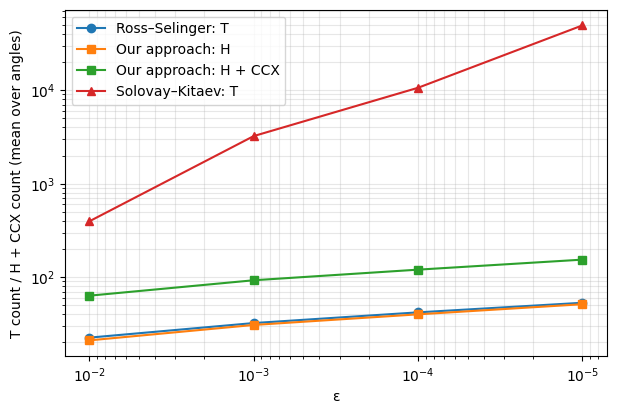

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4.5))
x = summary.index
sk_all = summary['SK reached'] == f"{len(ANGLES)}/{len(ANGLES)}"   # mean over a subset of angles is not comparable
ax.loglog(x, summary['RS T'], 'o-', label='Ross–Selinger: T')
ax.loglog(x, summary['ours H'], 's-', label=r'Our approach: H')
ax.loglog(x, summary['ours H'] + summary['ours CCX'], 's-', label=r'Our approach: H + CCX')
ax.loglog(x[sk_all], summary['SK T'][sk_all], '^-', label='Solovay–Kitaev: T')
ax.invert_xaxis(); ax.set_xlabel('ε'); ax.set_ylabel('T count / H + CCX count (mean over angles)')
ax.grid(True, which='both', alpha=.3); ax.legend()

# plt.savefig("decomp_comparison.png", dpi=200)
plt.show()

## 6. Plot: T cost (Ross–Selinger, SK) vs. Hadamard cost (ours)

## Notes

- **Our error is stricter.** It includes the phase exactly, while gridsynth and SK match $R_z(\theta)$ only up to a global phase. An exact-phase $P(\theta)$ from gridsynth needs $P(\theta)\otimes P(-\theta)$ on an extra qubit, which roughly doubles its T count.
- **Gate sets differ.** Clifford+T circuits cannot be realified gate by gate into H, X, Z, CX, CCX, because the realified T is not a Toffoli–Hadamard circuit. Within that gate set, the alternatives are rzsynth or Solovay–Kitaev.
- **Qiskit's SK has an error floor** of about 5e-8 with these settings, so ε ≤ 1e-8 is never reached.